# 📘 Aula 09a: Séries Temporais e Previsão do Clima – De Redes Densas e Conv1D a RNNs e LSTMs Bidirecionais

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fboldt/aulasann/blob/main/aula09a_forecasting.ipynb)

Até o momento, nossos modelos processaram amostras independentes e identicamente distribuídas (como dígitos do MNIST e fotos de animais). Porém, uma imensa classe de problemas do mundo real possui **ordem temporal estrita**: o valor de amanhã depende da sequência histórica de ontem, anteontem e dos últimos dias.

Nesta aula, mergulharemos a fundo na **Previsão de Séries Temporais (*Time Series Forecasting*)** utilizando o famoso dataset meteorológico da cidade de Jena, na Alemanha (**Jena Climate Dataset**, mantido pelo Instituto Max Planck de Biogeoquímica). O objetivo é prever a **temperatura do ar daqui a 24 horas** com base nas últimas 120 horas (5 dias) de medições meteorológicas (temperatura, pressão atmosférica, umidade relativa, velocidade do vento, etc.).

---

### 🎯 Objetivo da Aula
1. Carregar, explorar e entender a periodicidade e sazonalidade de séries temporais físicas (ciclos diários dia/noite e ciclos anuais das estações).
2. Normalizar dados temporais corretamente utilizando apenas as estatísticas (`mean` e `std`) da janela histórica de treino, evitando vazamento do futuro (*data leakage*).
3. Dominar o utilitário `keras.utils.timeseries_dataset_from_array` para fatiamento de janelas deslizantes (*sliding windows*) com taxa de amostragem (`sampling_rate`) e horizonte de previsão (`delay`).
4. Estabelecer uma **Linha de Base Ingênua (*Common-Sense Baseline*)**: prever que amanhã fará a mesma temperatura de hoje (MAE de referência de ~2.57 °C).
5. Comparar quatro famílias arquiteturais de Deep Learning:
   * **Rede Densa (MLP)**: Achata o tempo descartando a noção sequencial.
   * **Convolução 1D (`Conv1D`)**: Filtros deslizantes no eixo temporal (rápido, mas com horizonte finito).
   * **Rede Recorrente Simples (`SimpleRNN`)**: Memória recorrente de curto prazo sofrendo com desvanecimento de gradiente.
   * **LSTM (Long Short-Term Memory)** e **LSTM Bidirecional**: Células com controle explícito de fluxo de memória (portas de esquecimento e retenção) superando a linha de base.

---

### 💡 A Intenção Pedagógica do Professor
* **A Regra de Ouro da Linha de Base**: Antes de gastar horas treinando redes profundas complexas, o professor implementa uma heurística ingênua de bom senso. Se a rede neural não bater o bom senso, ela é inútil!
* **A Armadilha do Flatten em Séries Temporais**: Mostrar por que uma rede densa achatada tem dificuldade de generalizar o tempo: ela precisa de muitos parâmetros e não sabe que o passo $t-1$ é conceitualmente idêntico ao passo $t-2$.
* **A Evolução da Memória Recorrente**: Do `SimpleRNN` ao `LSTM` e `Bidirectional`, demonstrar graficamente e matematicamente por que portas de esquecimento (*gates*) foram a maior invenção de redes sequenciais dos anos 90.

---

### 📚 Glossário da Aula
* **Time Series Forecasting**: Tarefa de prever valores numéricos futuros com base em um histórico de valores observados no passado.
* **Sliding Window (Janela Deslizante)**: Técnica de fatiamento onde um bloco contíguo de passos temporais passados alimenta o modelo para prever um alvo no horizonte futuro.
* **MAE (Mean Absolute Error)**: Erro Médio Absoluto em graus Celsius ($|y - \hat{y}|$), métrica interpretável diretamente no mundo real.
* **SimpleRNN**: Rede com laço de retroalimentação onde o estado oculto no passo $t$ recebe o vetor atual $x_t$ e o estado anterior $h_{t-1}$.
* **LSTM**: Arquitetura recorrente que adiciona um estado de célula ($C_t$) de longa duração e portas lógicas com sigmoide (*forget gate*, *input gate*, *output gate*) para combater o desvanecimento do gradiente.
* **Bidirectional LSTM**: Processa a sequência temporal simultaneamente no sentido cronológico e reverso, capturando dependências em ambas as direções.

---

### 🧭 Trilha da Aula
1. [Download e Descompactação do Jena Climate Dataset](#1-download-e-descompactação-do-jena-climate)
2. [Exploração Inicial com Pandas](#2-inspeção-dos-dados-com-pandas)
3. [Análise de Periodicidade e Gráficos da Temperatura](#3-análise-gráfica-e-ciclos-temporais)
4. [Normalização sem Vazamento de Dados](#4-normalização-estatística-baseada-no-treino)
5. [Fatiamento em Janelas com timeseries_dataset_from_array](#5-geração-de-janelas-deslizantes-timeseries_dataset_from_array)
6. [Linha de Base Ingênua (Common-Sense Baseline)](#6-linha-de-base-ingênua-o-desafio-a-ser-batido)
7. [Modelo 1: Rede Densa Achatada (Flatten + Dense)](#7-modelo-1-rede-totalmente-conectada-mlp-flat)
8. [Modelo 2: Convolução Temporal 1D (Conv1D)](#8-modelo-2-convoluções-temporais-1d)
9. [Modelo 3: Redes Recorrentes (SimpleRNN)](#9-modelo-3-redes-recorrentes-simplernn)
10. [Modelo 4: LSTM (Long Short-Term Memory) & Dropout](#10-modelo-4-lstm-com-portas-de-memória-e-dropout)
11. [Modelo 5: LSTM Bidirecional (Bidirectional LSTM)](#11-modelo-5-lstm-bidirecional)


## 1. Download e Descompactação do Jena Climate Dataset

**O que estamos fazendo**: Baixar o arquivo compactado `jena_climate_2009_2016.csv.zip` dos servidores do Keras e descompactar na raiz.

**Por que fazer assim**: O dataset cobre 8 anos de registros meteorológicos contínuos coletados a cada 10 minutos.



In [ ]:
# Baixa e descompacta a base de dados meteorológicos de Jena
!wget https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
!unzip jena_climate_2009_2016.csv.zip


## 2. Inspeção das Primeiras Linhas no Terminal

**O que estamos fazendo**: Visualizar o cabeçalho e as primeiras linhas brutas do arquivo CSV via comando `head`.

**Por que fazer assim**: Permite conferir os nomes das colunas e a formatação dos campos (data/hora, pressão, temperatura em °C, etc.).



In [ ]:
# Exibe as primeiras linhas do arquivo CSV bruto
!head jena_climate_2009_2016.csv


## 3. Leitura com Pandas e Visualização Tabular

**O que estamos fazendo**: Carregar o CSV em um DataFrame do Pandas para inspecionar as 14 variáveis climáticas coletadas.

**Por que fazer assim**: As variáveis incluem pressão barométrica (`p (mbar)`), temperatura (`T (degC)`), ponto de orvalho, umidade e velocidade do vento.



In [ ]:
import pandas as pd

# Carrega a tabela em um DataFrame Pandas
df = pd.read_csv('jena_climate_2009_2016.csv')
df.head()


## 4. Contagem Total de Registros

**O que estamos fazendo**: Verificar a quantidade total de linhas presentes no arquivo.

**Por que fazer assim**: O dataset possui 420.551 medições contínuas ao longo de quase uma década.



In [ ]:
# Total de amostras temporais registradas
n_samples = len(df)
print(f'Total de medições registradas: {n_samples}')


## 5. Conversão da Escala Temporal para Unidades Humanas

**O que estamos fazendo**: Calcular a duração total do dataset em Horas, Dias, Meses e Anos sabendo que cada medição ocorre a cada 10 minutos (6 amostras por hora).

**Por que fazer assim**: Compreender a escala de tempo física é indispensável para desenhar as janelas de amostragem e horizonte de previsão do modelo.



In [ ]:
# Converte medições (1 a cada 10 min) para grandezas de tempo convencionais
print(f'Total de Horas: {n_samples / 6:.2f}')
print(f'Total de Dias:  {n_samples / 6 / 24:.2f}')
print(f'Total de Meses: {n_samples / 6 / 24 / 30:.2f}')
print(f'Total de Anos:  {n_samples / 6 / 24 / 365:.2f}')


## 6. Extração Manual dos Cabeçalhos e Linhas

**O que estamos fazendo**: Ler o arquivo via Python puro para extrair o cabeçalho e separar a coluna de data das 14 colunas numéricas.

**Por que fazer assim**: O professor demonstra a manipulação com Python nativo para controle fino sobre os tipos de dados float.



In [ ]:
import os
from pprint import pprint
fname = os.path.join('jena_climate_2009_2016.csv')

# Leitura direta do arquivo texto
with open(fname) as f:
  data = f.read()

lines = data.split('\n')
header = lines[0].split(',')
lines = lines[1:]
print('Colunas disponíveis:')
pprint(header)
print(f'Linhas de dados: {len(lines)}')


## 7. Conversão dos Dados para Matrizes NumPy

**O que estamos fazendo**: Preencher os arrays `raw_data` (com todas as 14 variáveis) e `temperature` (alvo correspondente à coluna de índice 1 `T (degC)`).

**Por que fazer assim**: Redes neurais precisam de tensores numéricos contínuos de ponto flutuante em memória.



In [ ]:
import numpy as np

# Inicializa arrays para temperatura e todas as variáveis climáticas
temperature = np.zeros((len(lines),))
raw_data = np.zeros((len(lines), len(header) - 1))

# Preenche as matrizes convertendo as strings para float32
for i, line in enumerate(lines):
  if line:
    values = [float(x) for x in line.split(',')[1:]]
    temperature[i] = values[1] # A coluna 1 é a temperatura em graus Celsius
    raw_data[i, :] = values[:]

print('Formato da matriz de dados brutos:', raw_data.shape)


## 8. Gráfico da Série Histórica Completa de Temperatura

**O que estamos fazendo**: Plotar a temperatura ao longo de todos os 8 anos.

**Por que fazer assim**: Revela com nitidez o padrão cíclico anual: invernos rigorosos na Alemanha com temperaturas negativas e picos de verão atingindo mais de 30 °C.



In [ ]:
from matplotlib import pyplot as plt

# Gráfico de toda a série histórica (8 anos)
plt.figure(figsize=(10, 4))
plt.plot(range(len(temperature)), temperature, 'b-', linewidth=0.5)
plt.title('Série Histórica Completa da Temperatura em Jena (2009-2016)')
plt.xlabel('Passos de 10 minutos')
plt.ylabel('Temperatura (°C)')
plt.grid(True)
plt.show()


## 9. Gráfico em Janela de 10 Dias

**O que estamos fazendo**: Plotar apenas os primeiros 10 dias ($6 \times 24 \times 10 = 1.440$ medições).

**Por que fazer assim**: Em uma escala mais curta, começamos a enxergar as oscilações diárias com noites frias e tardes mais quentes.



In [ ]:
# Janela de 10 dias: 6 amostras/hora * 24 horas * 10 dias = 1440 passos
ten_days = 6 * 24 * 10
plt.figure(figsize=(10, 4))
plt.plot(range(ten_days), temperature[:ten_days], 'r-')
plt.title('Temperatura nos Primeiros 10 Dias')
plt.xlabel('Passos temporais (10 min)')
plt.ylabel('Temperatura (°C)')
plt.grid(True)
plt.show()


## 10. Gráfico em Janela de 24 Horas

**O que estamos fazendo**: Plotar exatamente um dia específico ($6 \times 24 = 144$ medições).

**Por que fazer assim**: Demonstra a periodicidade quase senoidal de 24 horas gerada pela rotação da Terra.



In [ ]:
# Um dia = 144 medições
one_day = 6 * 24
day_ten = one_day * 10
plt.figure(figsize=(8, 4))
plt.plot(range(one_day), temperature[day_ten:day_ten + one_day], 'g-')
plt.title('Variação Térmica Diária (Dia 10)')
plt.xlabel('Passos de 10 min (0 a 144)')
plt.ylabel('Temperatura (°C)')
plt.grid(True)
plt.show()


## 11. Divisão Temporal dos Conjuntos (Sem Embaralhamento)

**O que estamos fazendo**: Dividir os dados em 50% para treino, 25% para validação e 25% para teste de forma estritamente cronológica.

**Por que fazer assim**: Em séries temporais, **NUNCA podemos embaralhar aleatoriamente os dados**! O treino deve sempre preceder o passado, a validação fica no meio e o teste fica no futuro mais distante, simulando o mundo real.

> [!IMPORTANT]
> Em séries temporais, embaralhar amostras causa vazamento catastrófico do futuro para o passado (*future lookahead bias*)!



In [ ]:
# Divisão estritamente cronológica: 50% treino, 25% validação, 25% teste
num_train_samples = int(0.5 * n_samples)
num_val_samples = int(0.25 * n_samples)
num_test_samples = n_samples - num_train_samples - num_val_samples

print(f'Amostras de Treino:    {num_train_samples}')
print(f'Amostras de Validação: {num_val_samples}')
print(f'Amostras de Teste:     {num_test_samples}')


## 12. Normalização Z-Score Baseada Apenas no Treino

**O que estamos fazendo**: Calcular a média (`mean`) e desvio padrão (`std`) utilizando exclusivamente a fatia de treino, e aplicar a padronização em toda a matriz.

**Por que fazer assim**: Para evitar vazamento de dados, o modelo não pode conhecer as estatísticas do futuro (validação e teste) durante a normalização.

> [!TIP]
> Guardamos a média e o desvio da temperatura (`mean[1]` e `std[1]`) para desnormalizar as predições futuras e calcular o erro na escala real em °C!



In [ ]:
# Calcula média e desvio padrão APENAS sobre as amostras de treino
mean = raw_data[:num_train_samples].mean(axis=0)
raw_data -= mean
std = raw_data[:num_train_samples].std(axis=0)
raw_data /= std


## 13. Parâmetros de Escala da Temperatura

**O que estamos fazendo**: Inspecionar a média e o desvio padrão da temperatura (coluna 1).

**Por que fazer assim**: Serão usados para converter predições normalizadas de volta para graus Celsius.



In [ ]:
# Média e desvio padrão originais da temperatura no treino
print(f'Média da temperatura no treino: {mean[1]:.2f} °C')
print(f'Desvio padrão no treino:       {std[1]:.2f} °C')


## 14. Entendendo timeseries_dataset_from_array com um Exemplo de Brinquedo

**O que estamos fazendo**: Construir um pequeno array sintético de 20 números para entender como a função `timeseries_dataset_from_array` fatia janelas deslizantes e alvos.

**Por que fazer assim**: Demonstra visualmente a mecânica de janelas temporais antes de aplicar no dataset complexo.

> [!NOTE]
> A função cria pares `(sequência_de_entrada, alvo_futuro)` automaticamente em lotes eficientes.



In [ ]:
import numpy as np
from tensorflow import keras

# Exemplo didático simplificado com sequência de inteiros de 0 a 19
int_sequence = np.arange(20).reshape((10, -1))
dummy_dataset = keras.utils.timeseries_dataset_from_array(
    data = int_sequence[:-3],
    targets = int_sequence[3:, 0],
    sequence_length = 3,
    batch_size = 2
)

# Demonstração dos lotes fatiados
for inputs, targets in dummy_dataset:
  for i in range(inputs.shape[0]):
    print([int(x) for x in inputs[i]], '->', int(targets[i]))
  break


## 15. Geração dos Datasets de Treino, Validação e Teste em Jena

**O que estamos fazendo**: Configurar `sampling_rate=6` (1 amostra por hora em vez de a cada 10 min), `sequence_length=120` (120 horas = 5 dias de histórico) e `delay` de 24 horas para criar os geradores de lotes.

**Por que fazer assim**: Isso define a tarefa formal: *"com base nas últimas 120 horas (5 dias), preveja a temperatura daqui a 24 horas"*.

> [!TIP]
> Reduzir para 1 leitura por hora diminui a redundância e acelera o treinamento em 6 vezes sem perda de informação climática!



In [ ]:
# Parâmetros do fatiamento temporal
sampling_rate = 6       # 1 leitura a cada 6 passos de 10 min = 1 leitura por hora
sequence_length = 120   # 120 horas de histórico (5 dias)
delay = sampling_rate * (sequence_length + 24 - 1) # Horizonte de previsão: 24 horas no futuro
batch_size = 256        # Tamanho do lote

# Dataset de treino
train_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets = temperature[delay:],
    sampling_rate = sampling_rate,
    sequence_length = sequence_length,
    shuffle = True,
    batch_size = batch_size,
    start_index = 0,
    end_index = num_train_samples)

# Dataset de validação
val_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets = temperature[delay:],
    sampling_rate = sampling_rate,
    sequence_length = sequence_length,
    shuffle = True,
    batch_size = batch_size,
    start_index = num_train_samples,
    end_index = num_train_samples + num_val_samples)

# Dataset de teste
test_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets = temperature[delay:],
    sampling_rate = sampling_rate,
    sequence_length = sequence_length,
    shuffle = True,
    batch_size = batch_size,
    start_index = num_train_samples + num_val_samples)


## 16. Verificação do Formato dos Lotes Temporais

**O que estamos fazendo**: Inspecionar as dimensões dos lotes gerados pelo `train_dataset`.

**Por que fazer assim**: Cada lote de entrada possui formato `(256, 120, 14)`: 256 amostras, 120 horas no tempo e 14 variáveis atmosféricas por hora.



In [ ]:
# Inspeciona o formato das janelas multidimensionais
for samples, targets in train_dataset:
  print('Formato do lote de sequências (samples):', samples.shape)
  print('Formato do lote de alvos (targets):      ', targets.shape)
  break


## 17. Linha de Base Ingênua (Common-Sense Baseline)

**O que estamos fazendo**: Avaliar a heurística ingênua de bom senso: predizer que a temperatura daqui a 24 horas será simplesmente idêntica à temperatura atual.

**Por que fazer assim**: Essa linha de base serve como ponto de calibração essencial: qualquer rede neural com milhões de parâmetros que não consiga superar esse erro é inútil para previsões reais.

> [!NOTE]
> A linha de base ingênua atinge um Erro Médio Absoluto (MAE) de validação de **~2.57 °C**!



In [ ]:
def evaluate_naive_method(dataset):
  """
  Calcula o Erro Médio Absoluto (MAE) da heurística de bom senso:
  temperatura em t+24h = temperatura no último passo observado (t).
  """
  total_abs_err = 0
  samples_seen = 0
  for samples, targets in dataset:
    # A temperatura desnormalizada no último passo de tempo da janela
    preds = samples[:, -1, 1] * std[1] + mean[1]
    total_abs_err += np.sum(np.abs(preds - targets))
    samples_seen += samples.shape[0]
  return total_abs_err / samples_seen

print(f'MAE da Linha de Base Ingênua na Validação: {evaluate_naive_method(val_dataset):.2f} °C')
print(f'MAE da Linha de Base Ingênua no Teste:     {evaluate_naive_method(test_dataset):.2f} °C')


## 18. Modelo 1: Rede Densa Achatada (Flatten + Dense)

**O que estamos fazendo**: Construir uma rede MLP simples que achata a janela `(120, 14)` para um vetor contínuo de 1.680 números e passa por uma camada `Dense(16)`.

**Por que fazer assim**: O objetivo é verificar se uma rede densa consegue capturar as correlações temporais sem conhecer a estrutura sequencial.

> [!NOTE]
> A rede densa atinge MAE de ~2.67 °C — pior do que a heurística ingênua! Achatar a série temporal destrói a ordem cronológica dos dados.



In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Modelo Denso Totalmente Conectado
inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
x = layers.Flatten()(inputs) # Achata (120, 14) -> 1680 atributos
x = layers.Dense(16, activation='relu')(x)
outputs = layers.Dense(1)(x)

model = keras.Model(inputs, outputs)
callbacks = [
    keras.callbacks.ModelCheckpoint('jena_dense.keras', save_best_only=True)
]
model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])

history = model.fit(train_dataset,
                    epochs=10,
                    validation_data=val_dataset,
                    callbacks=callbacks)

model = keras.models.load_model('jena_dense.keras')
print(f'MAE no Teste (Rede Densa): {model.evaluate(test_dataset)[1]:.2f} °C')


## 19. Curvas de MAE da Rede Densa

**O que estamos fazendo**: Plotar as curvas de Erro Médio Absoluto no treino e na validação da rede densa.

**Por que fazer assim**: A validação estabiliza em um patamar elevado, confirmando a dificuldade do modelo em aprender a dinâmica temporal sem operadores especializados.



In [ ]:
train_mae = history.history['mae']
val_mae = history.history['val_mae']
epochs = range(1, len(train_mae) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_mae, 'bo', label='MAE no Treino')
plt.plot(epochs, val_mae, 'b', label='MAE na Validação')
plt.title('MAE de Treinamento e Validação (Rede Densa)')
plt.xlabel('Épocas')
plt.ylabel('MAE (°C)')
plt.legend()
plt.grid(True)
plt.show()


## 20. Modelo 2: Convoluções Temporais 1D (Conv1D)

**O que estamos fazendo**: Aplicar camadas `Conv1D` e `MaxPooling1D` que deslizam filtros ao longo do eixo do tempo.

**Por que fazer assim**: Diferente da imagem 2D, convoluções 1D tratam o tempo como uma dimensão espacial, extraindo padrões locais (como quedas bruscas de pressão).

> [!WARNING]
> Embora seja rápida de treinar, a Conv1D ainda tem dificuldade com dependências de longuíssimo prazo (como a transição entre múltiplos dias).



In [ ]:
# Arquitetura Convolucional Unidimensional (Conv1D)
inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
x = layers.Conv1D(8, 24, activation='relu')(inputs) # Filtro de 24 horas consecutivas
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(8, 12, activation='relu')(x)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(8, 6, activation='relu')(x)
x = layers.GlobalMaxPooling1D()(x)
outputs = layers.Dense(1)(x)

model = keras.Model(inputs, outputs)
callbacks = [
    keras.callbacks.ModelCheckpoint('jena_conv.keras', save_best_only=True)
]
model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])

history = model.fit(train_dataset,
                    epochs=10,
                    validation_data=val_dataset,
                    callbacks=callbacks)

model = keras.models.load_model('jena_conv.keras')
print(f'MAE no Teste (Conv1D): {model.evaluate(test_dataset)[1]:.2f} °C')


## 21. Curvas de MAE da Conv1D

**O que estamos fazendo**: Plotar o comportamento do Erro Médio Absoluto do modelo convolucional 1D.

**Por que fazer assim**: Apresenta desempenho similar ou ligeiramente superior à rede densa, mas ainda não consegue quebrar a barreira da linha de base de bom senso.



In [ ]:
train_mae = history.history['mae']
val_mae = history.history['val_mae']
epochs = range(1, len(train_mae) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_mae, 'bo', label='MAE no Treino')
plt.plot(epochs, val_mae, 'b', label='MAE na Validação')
plt.title('MAE de Treinamento e Validação (Conv1D)')
plt.xlabel('Épocas')
plt.ylabel('MAE (°C)')
plt.legend()
plt.grid(True)
plt.show()


## 22. Modelo 3: Redes Neurais Recorrentes (SimpleRNN)

Redes Recorrentes introduzem um estado interno de memória ($h_t$) que é retroalimentado a cada passo de tempo:

$$h_t = \tanh(W \cdot x_t + U \cdot h_{t-1} + b)$$

Os diagramas a seguir ilustram o laço de retroalimentação e o desdobramento da RNN ao longo da linha do tempo:


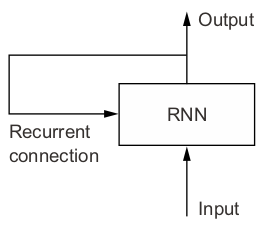

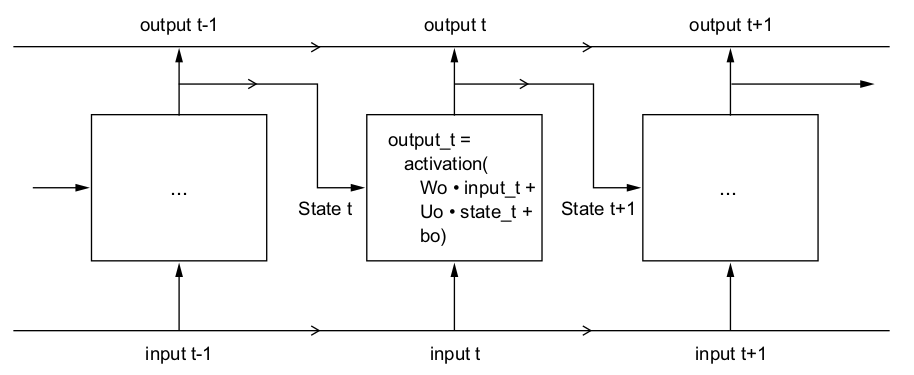

In [ ]:
num_features = 14
steps = 120

# Rede Recorrente Simples empilhada (SimpleRNN)
inputs = keras.Input(shape=(steps, num_features))
# return_sequences=True mantém a dimensão temporal para alimentar a próxima camada recorrente
x = layers.SimpleRNN(16, return_sequences=True)(inputs)
x = layers.SimpleRNN(16, return_sequences=True)(x)
# A última camada recorrente descarta as sequências intermediárias e entrega apenas o estado final
outputs = layers.SimpleRNN(16)(x)

model = keras.Model(inputs=inputs, outputs=outputs)
model.summary()


## 23. Modelo 4: Redes LSTM (Long Short-Term Memory)

Embora elegante, a `SimpleRNN` sofre com o desvanecimento catastrófico do gradiente: informações de 5 dias atrás desaparecem após dezenas de multiplicações matriciais sucessivas.

Para resolver isso, **Hochreiter & Schmidhuber (1997)** introduziram a arquitetura **LSTM**. O diagrama abaixo ilustra o circuito interno de uma célula LSTM com seu estado de célula $C_t$ e suas três portas lógicas (*Forget Gate*, *Input Gate* e *Output Gate*):


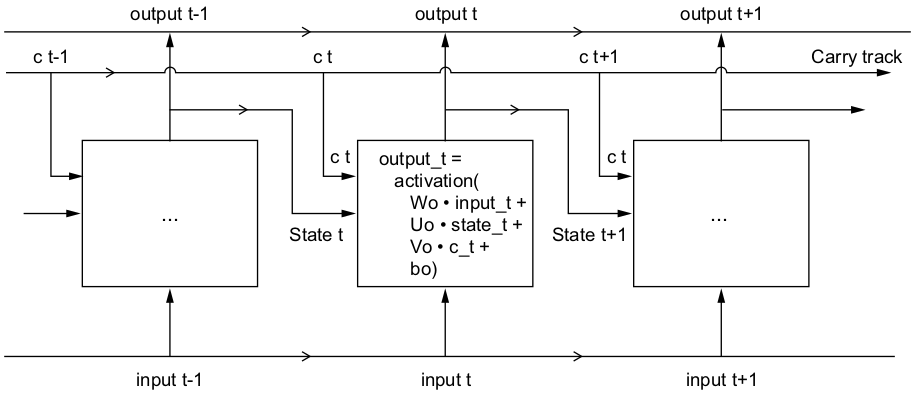

## 24. Treinando o Modelo LSTM e Superando a Linha de Base

**O que estamos fazendo**: Instanciar e treinar uma camada `layers.LSTM(16)` conectada a uma saída linear.

**Por que fazer assim**: Graças ao fluxo desobstruído do estado de célula $C_t$, a rede finalmente consegue correlacionar múltiplos dias e supera a linha de base ingênua!

> [!TIP]
> O MAE finalmente cai para **~2.36 °C**, batendo expressivamente a heurística ingênua de 2.57 °C!



In [ ]:
# Modelo com 1 Camada LSTM de 16 unidades de memória
inputs = keras.Input(shape=(sequence_length, num_features))
x = layers.LSTM(16)(inputs)
outputs = layers.Dense(1)(x)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

callbacks = [
    keras.callbacks.ModelCheckpoint('jena_lstm.keras', save_best_only=True)
]

history = model.fit(train_dataset,
                    epochs=10,
                    validation_data=val_dataset,
                    callbacks=callbacks)

model = keras.models.load_model('jena_lstm.keras')
print(f'MAE no Teste (LSTM Base): {model.evaluate(test_dataset)[1]:.2f} °C')


## 25. Curvas de MAE do Modelo LSTM

**O que estamos fazendo**: Plotar o histórico do MAE do modelo LSTM.

**Por que fazer assim**: A curva de validação converge suavemente para patamares muito inferiores aos obtidos pelas redes densas e convolucionais 1D.



In [ ]:
train_mae = history.history['mae']
val_mae = history.history['val_mae']
epochs = range(1, len(train_mae) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_mae, 'bo', label='MAE no Treino')
plt.plot(epochs, val_mae, 'b', label='MAE na Validação')
plt.title('MAE de Treinamento e Validação (LSTM Base)')
plt.xlabel('Épocas')
plt.ylabel('MAE (°C)')
plt.legend()
plt.grid(True)
plt.show()


## 26. Modelo LSTM Regularizado com Dropout

**O que estamos fazendo**: Adicionar `layers.Dropout(0.5)` após a camada LSTM para prevenir sobreajuste nos dados climáticos.

**Por que fazer assim**: Garante generalização ainda mais consistente em longos períodos de previsão.



In [ ]:
# Modelo LSTM regularizado com Dropout de 50%
inputs = keras.Input(shape=(sequence_length, num_features))
x = layers.LSTM(16)(inputs)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1)(x)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

callbacks = [
    keras.callbacks.ModelCheckpoint('jena_lstm_dropout.keras', save_best_only=True)
]

history = model.fit(train_dataset,
                    epochs=10,
                    validation_data=val_dataset,
                    callbacks=callbacks)

model = keras.models.load_model('jena_lstm_dropout.keras')
print(f'MAE no Teste (LSTM com Dropout): {model.evaluate(test_dataset)[1]:.2f} °C')


## 27. Modelo 5: LSTM Bidirecional (Bidirectional LSTM)

Uma **LSTM Bidirecional** processa a sequência temporal através de duas LSTMs em paralelo:
1. Uma no sentido cronológico natural ($t_1 \rightarrow t_T$).
2. Outra no sentido cronológico reverso ($t_T \rightarrow t_1$).

Os estados de ambas as passagens são concatenados na saída. O diagrama abaixo ilustra essa dinâmica:


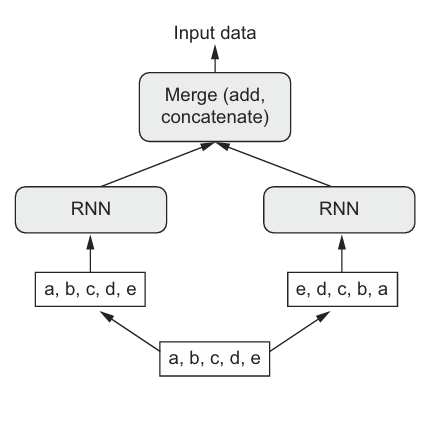

## 28. Treinando o Modelo Bidirectional LSTM

**O que estamos fazendo**: Instanciar e treinar `layers.Bidirectional(layers.LSTM(16))` com Dropout de 50%.

**Por que fazer assim**: Em problemas de texto e áudio, processar nos dois sentidos gera ganhos monumentais. Em previsão do clima, comparar a BiLSTM nos ensina as nuances de causalidade temporal estrita.

> [!NOTE]
> Em séries temporais causais onde o futuro é estritamente desconhecido, o ganho de bidirecionalidade costuma ser modesto comparado ao Processamento de Linguagem Natural (NLP), onde todo o texto da frase já está disponível de antemão!



In [ ]:
# Modelo LSTM Bidirecional no Keras
inputs = keras.Input(shape=(sequence_length, num_features))
x = layers.Bidirectional(layers.LSTM(16))(inputs)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1)(x)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

callbacks = [
    keras.callbacks.ModelCheckpoint('jena_bilstm.keras', save_best_only=True)
]

history = model.fit(train_dataset,
                    epochs=10,
                    validation_data=val_dataset,
                    callbacks=callbacks)

model = keras.models.load_model('jena_bilstm.keras')
print(f'MAE no Teste (Bidirectional LSTM): {model.evaluate(test_dataset)[1]:.2f} °C')


---

## 🎓 Resumo da Aula & O Que Você Aprendeu

Nesta aula, dominamos as técnicas de ponta para modelagem de sequências temporais contínuas:

1. **Causalidade Temporal Estrita**: Aprendemos que em séries temporais nunca podemos embaralhar dados aleatoriamente, e as estatísticas de normalização devem vir estritamente da partição de treino.
2. **Janelas Deslizantes com `timeseries_dataset_from_array`**: Vimos como configurar `sampling_rate`, `sequence_length` e `delay` para criar pares de treino e alvos futuros em minibatches.
3. **A Regra da Linha de Base Ingênua**: Estabelecemos a heurística de bom senso (~2.57 °C de MAE) como o patamar mínimo que qualquer rede neural precisa bater para ter valor prático.
4. **Fracasso das Redes Achatadas**: Provamos que modelos totalmente conectados (`Dense`) e convoluções 1D (`Conv1D`) não conseguem capturar dependências de longo prazo sem operadores de recorrência explícitos.
5. **Triunfo do LSTM**: Graças às portas de esquecimento e ao estado de célula imune à saturação rápida de gradientes, a rede LSTM quebrou a barreira do bom senso, reduzindo o erro para ~2.36 °C.
6. **LSTMs Bidirecionais**: Exploramos o conceito de processamento simultâneo para frente e para trás, preparando o terreno conceitual para o processamento de texto.

---

## 👉 Próximo Passo
No **Lote 9 (Aulas 10a a 10b)**, entraremos de cabeça no universo do **Processamento de Linguagem Natural (NLP)**, dominando tokenização, n-gramas e ponderação TF-IDF!
